# ZollerQu: long/short stock split (Qollab × IonQ hackathon)

This effort is supported by Qollab & IonQ.

Working notebook, built cell by cell. Local development only: the Qollab entry point will be a separate `main.py`, and the reusable code lives in the `stocks/` package next to this notebook.

## Task 1: Load and validate the OR-Library dataset

Source: J E Beasley, OR-Library, `indtrack1.txt` (index tracking problem 1, MIT licence). Downloaded once during development; nothing is downloaded at run time.

In [1]:
import hashlib
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "stocks").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from stocks import data, validate_data

print("repo root:", ROOT)

repo root: /Users/t/zollerqu-qollab


### 1.1 Source file as downloaded

In [2]:
raw = data.RAW_PATH
lines = raw.read_text().splitlines()
print("file:  ", raw.relative_to(ROOT), f"({raw.stat().st_size} bytes)")
print("sha256:", hashlib.sha256(raw.read_bytes()).hexdigest())
print("line 1:", repr(lines[0]))
print("line 2:", repr(lines[1]))
values_per_line = [len(line.split()) for line in lines[1:]]
print("lines after header:", len(values_per_line),
      "| with 4 values:", values_per_line.count(4),
      "| with 3 values:", values_per_line.count(3),
      "| total values:", sum(values_per_line))

file:   data/raw/indtrack1.txt (116665 bytes)
sha256: 258b917e304e21c87ae481b9baba0aefe877b657fa63483255c23162a74aa629
line 1: ' 31 290 '
line 2: ' 8749.31759356 8713.53262793 9001.60515134 8903.30299873 '
lines after header: 2336 | with 4 values: 2304 | with 3 values: 32 | total values: 9312


### 1.2 Parse and validate

`parse_orlib` accepts a layout only if the price count matches it **and** every series starts on a new line. It also checks that the first index price is near 8749 and that all prices are finite and positive. Any problem raises `DataFormatError`; nothing is dropped or filled in.

In [3]:
market, report = data.parse_orlib(raw)
print(report)
print("index:", market.index.shape, "| stocks:", market.prices.shape, "| names:", market.names[0], "...", market.names[-1])
print("first index price:", float(market.index[0]))
print(f"index range {market.index.min():.2f} .. {market.index.max():.2f} | "
      f"stock range {market.prices.min():.4f} .. {market.prices.max():.4f}")

ParseReport(header=(31, 290), n_values=9312, layout='(N+1)*(T+1)', n_series=32, observations=291)
index: (291,) | stocks: (291, 31) | names: s01 ... s31
first index price: 8749.31759356
index range 8713.53 .. 29550.18 | stock range 1.7928 .. 484.5881


### 1.3 Normalised CSV `data/hangseng_weekly.csv`

One row per observation: `week,index,s01,...,s31`. The source has no dates, so `week` is the observation number 0..290 in source order.

In [4]:
data.write_csv(market, data.CSV_PATH)
reloaded = data.load_csv(data.CSV_PATH)
same = (reloaded.names == market.names
        and (reloaded.index == market.index).all()
        and (reloaded.prices == market.prices).all())
print("reloaded identical to the parsed source:", same)
for line in data.CSV_PATH.read_text().splitlines()[:3]:
    print(line[:100] + " ...")

reloaded identical to the parsed source: True
week,index,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21,s22,s ...
0,8749.31759356,9.33675195,14.37788798,7.36644878,29.46579511,5.55589992,8.55573087,16.41919306,9.95 ...
1,8713.53262793,9.86926631,14.18263271,7.40194974,27.33573763,5.44939705,8.50247943,16.41919306,9.28 ...


### 1.4 Licence notice

In [5]:
ok, message = validate_data.check_licence()
print(message)
print()
print("\n".join(data.LICENSE_PATH.read_text().splitlines()[:10]))

verified (data/LICENSE_ORLIB.txt holds the full MIT notice, copied verbatim from OR-Library legal.html)

OR-Library licence notice for data/raw/indtrack1.txt and data/hangseng_weekly.csv

Data:    indtrack1.txt (index tracking test problem 1), OR-Library, J E Beasley
         https://people.brunel.ac.uk/~mastjjb/jeb/orlib/files/indtrack1.txt
Notice:  copied verbatim from https://people.brunel.ac.uk/~mastjjb/jeb/orlib/legal.html
         on 2026-10-10. Only the HTML markup was removed; the wording, line breaks and
         the original "(J E Beasley}" bracket are unchanged.
Changes: data/hangseng_weekly.csv holds the same prices rearranged into columns by
         stocks/data.py (team ZollerQu). No values were added, removed or altered.


### 1.5 Task 1 report (also runs the 23 unit tests)

Same output as `python -m stocks.validate_data` from the repo root.

In [6]:
exit_code = validate_data.main()

[TASK 1] OR-Library dataset validation
- Source: original OR-Library file data/raw/indtrack1.txt (sha256 258b917e304e21c8...)
- Header: 31 290
- Layout: (N+1)*(T+1) = 32 series x 291 = 9312 prices, each series starting on a new line
- Stock series: 31
- Index series: 1
- Price observations per series: 291 (index: 291)
- First index price: 8749.31759356
- Invalid or missing prices: 0 (counted in the written CSV)
- CSV output: data/hangseng_weekly.csv (291 rows x 33 columns, reload identical to source: yes)
- Licence notice: verified (data/LICENSE_ORLIB.txt holds the full MIT notice, copied verbatim from OR-Library legal.html)
- Tests: 23 passed, 0 failed
RESULT: PASS


### 1.6 What the data contains

Price summary for all 31 stocks and the index, then a sample of the weekly prices. The source file has no company names or dates: stocks are labelled `s01`..`s31` in file order and `week` is the observation number. Prices are in the units of the source file.

In [7]:
import pandas as pd

pd.set_option("display.float_format", "{:,.2f}".format)
df = pd.read_csv(data.CSV_PATH).set_index("week")
series = ["index"] + market.names
first, last = df[series].iloc[0], df[series].iloc[-1]
summary = pd.DataFrame({
    "first price (week 0)": first,
    "last price (week 290)": last,
    "lowest": df[series].min(),
    "highest": df[series].max(),
    "change week 0 to 290 (%)": (last / first - 1) * 100,
})
summary.index.name = "series"
print(f"{len(market.names)} stocks + 1 index, {len(df)} weekly prices each (weeks {df.index[0]} to {df.index[-1]})")
summary

31 stocks + 1 index, 291 weekly prices each (weeks 0 to 290)


,first price (week 0),last price (week 290),lowest,highest,change week 0 to 290 (%)
series,,,,,
index,"8,749.32","25,532.52","8,713.53","29,550.18",191.82
s01,9.34,17.13,8.73,27.34,83.46
s02,14.38,48.28,14.18,57.33,235.80
s03,7.37,8.25,7.01,17.93,12.05
s04,29.47,123.81,24.85,143.34,320.18
s05,5.56,15.98,5.33,16.69,187.54
s06,8.56,26.98,8.50,29.64,215.35
s07,16.42,41.36,15.80,55.47,151.89
s08,9.96,14.56,8.43,23.79,46.17


In [8]:
sample = ["index", "s01", "s02", "s03", "s04", "s05", "s06"]
print("Sample: first 5 and last 5 weeks, index + stocks s01 to s06")
pd.concat([df[sample].head(5), df[sample].tail(5)])

Sample: first 5 and last 5 weeks, index + stocks s01 to s06


,index,s01,s02,s03,s04,s05,s06
week,,,,,,,
0,"8,749.32",9.34,14.38,7.37,29.47,5.56,8.56
1,"8,713.53",9.87,14.18,7.40,27.34,5.45,8.50
2,"9,001.61",9.96,14.59,7.77,28.76,5.80,8.73
3,"8,903.30",9.16,15.74,7.63,28.76,5.50,8.86
4,"8,888.69",9.25,16.29,7.49,27.87,5.50,9.21
286,"27,388.55",17.57,53.78,8.47,135.79,15.89,29.11
287,"25,090.75",16.86,49.08,8.22,114.49,14.56,25.56
288,"25,851.00",17.04,48.28,7.77,126.03,15.53,27.34
289,"25,685.76",17.04,48.81,8.29,126.03,15.00,27.42


### 1.7 Stock names: not available in the data

The company names are **not in the dataset, and no public source we found lists them**. The FRAPO R package documentation for this data (INDTRACK1) says: *"The data was downloaded from DATASTREAM and has been anonymized"*, and describes it as weekly prices of the Hang Seng index and 31 of its constituents, March 1991 to September 1997. OR-Library gives no names either.

- `s01`..`s31` are simply the order of the stocks in the source file.
- We do **not** guess names from price patterns: a guess could not be verified and would undo the anonymisation.
- Consequence for the project: results describe the method on real 1990s Hong Kong stock prices, not named companies. Named stocks would need a different price dataset that we are licensed to ship.

### 1.8 Price paths of all 31 stocks and the index

Every series is rebased to 100 at week 0, so all paths start at the same point and can be compared. Log scale, so a doubling looks the same size everywhere. Grey: stocks; blue: the index; orange: the stock with the largest rise. The exact numbers are in the table in 1.6.

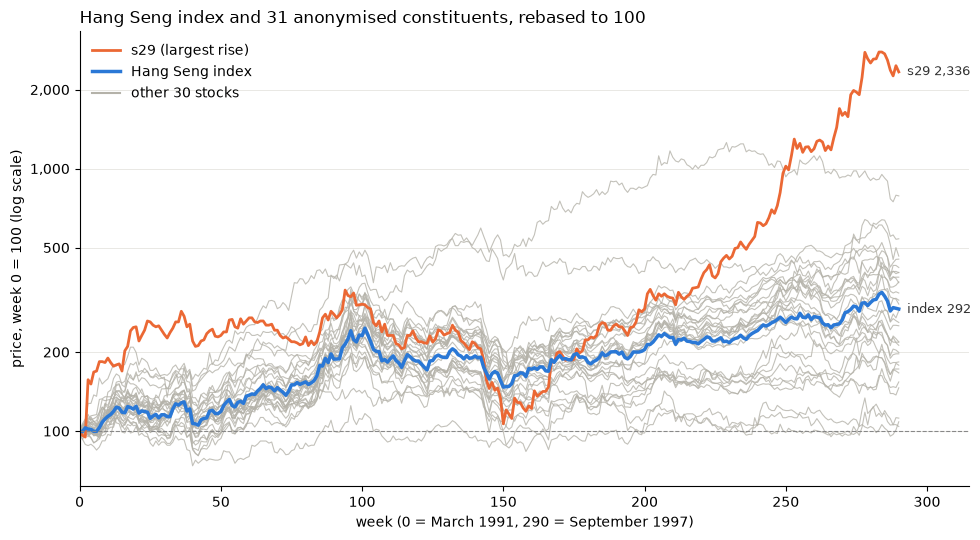

Text summary: the index ends at 292 (start = 100). 31 of 31 stocks end above 100; the median stock ends at 259; 14 stocks end above the index. Largest rise: s29 at 2,336; smallest: s14 at 104.


In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

rebased = df[series] / df[series].iloc[0] * 100
final = rebased.iloc[-1]
top = final[market.names].idxmax()

fig, ax = plt.subplots(figsize=(10, 5.5))
for name in market.names:
    if name != top:
        ax.plot(rebased.index, rebased[name], color="#b4b2a9", linewidth=0.8, alpha=0.8)
ax.plot(rebased.index, rebased[top], color="#eb6834", linewidth=2, label=f"{top} (largest rise)")
ax.plot(rebased.index, rebased["index"], color="#2a78d6", linewidth=2.5, label="Hang Seng index")
ax.plot([], [], color="#b4b2a9", linewidth=1.5, label="other 30 stocks")

ax.set_yscale("log")
ax.yaxis.set_major_locator(FixedLocator([50, 100, 200, 500, 1000, 2000]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_locator(FixedLocator([]))
for name, color in [(top, "#eb6834"), ("index", "#2a78d6")]:
    label = "index" if name == "index" else name
    ax.annotate(f"{label} {final[name]:,.0f}", (rebased.index[-1], final[name]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#333333")
ax.axhline(100, color="#888888", linewidth=0.8, linestyle="--")
ax.set_xlim(0, rebased.index[-1] + 25)
ax.set_xlabel("week (0 = March 1991, 290 = September 1997)")
ax.set_ylabel("price, week 0 = 100 (log scale)")
ax.set_title("Hang Seng index and 31 anonymised constituents, rebased to 100", loc="left")
ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

stocks_final = final[market.names]
print(f"Text summary: the index ends at {final['index']:.0f} (start = 100). "
      f"{(stocks_final > 100).sum()} of {len(stocks_final)} stocks end above 100; the median stock ends at "
      f"{stocks_final.median():.0f}; {(stocks_final > final['index']).sum()} stocks end above the index. "
      f"Largest rise: {stocks_final.idxmax()} at {stocks_final.max():,.0f}; smallest: "
      f"{stocks_final.idxmin()} at {stocks_final.min():.0f}.")

## Kaggle dataset: named US stocks and ETFs (first look)

Source: Boris Marjanovic, *Huge Stock Market Dataset*, Kaggle, licence **CC0 (public domain)**. Daily prices of US stocks and ETFs (exchange-traded funds), adjusted for dividends and splits, up to 10 Nov 2017. Downloaded 2026-10-10 to `data/raw/kaggle/archive.zip`. The archive is 515 MB, so it is **not in git**; we will ship only a small CSV of the assets we choose. To get it, no login needed:

`curl -L -o data/raw/kaggle/archive.zip https://www.kaggle.com/api/v1/datasets/download/borismarjanovic/price-volume-data-for-all-us-stocks-etfs`

The archive contains every file twice (`Data/ETFs` = `ETFs`, `Data/Stocks` = `Stocks`, identical checksums); we read `ETFs/` and `Stocks/` only.

### K.1 What is in the archive

In [10]:
import zipfile

KAGGLE_ZIP = ROOT / "data" / "raw" / "kaggle" / "archive.zip"
if not KAGGLE_ZIP.is_file():
    raise FileNotFoundError(f"{KAGGLE_ZIP} not found: download it with the curl command above")
zf = zipfile.ZipFile(KAGGLE_ZIP)

rows = []
for info in zf.infolist():
    folder, _, filename = info.filename.partition("/")
    if folder not in ("ETFs", "Stocks") or not filename.endswith(".us.txt"):
        continue
    ticker = filename.removesuffix(".us.txt").upper()
    lines = zf.read(info).decode().splitlines() if info.file_size else []
    if len(lines) > 1:
        rows.append((ticker, folder, lines[1][:10], lines[-1][:10], len(lines) - 1))
    else:
        rows.append((ticker, folder, None, None, 0))
inventory = pd.DataFrame(rows, columns=["ticker", "type", "first day", "last day", "trading days"])

has_data = inventory["trading days"] > 0
overview = inventory.groupby("type").agg(
    files=("ticker", "size"),
    empty_files=("trading days", lambda d: int((d == 0).sum())),
    earliest_day=("first day", "min"),
    latest_day=("last day", "max"),
    median_trading_days=("trading days", lambda d: int(d[d > 0].median())),
)
print(f"{len(inventory):,} files: {has_data.sum():,} with prices, {(~has_data).sum()} empty")
overview

8,539 files: 8,507 with prices, 32 empty


,files,empty_files,earliest_day,latest_day,median_trading_days
type,,,,,
ETFs,1344,0,1999-03-10,2017-11-10,1923
Stocks,7195,32,1962-01-02,2017-11-10,1818


### K.2 Suggested named assets, in groups

A first suggestion to discuss, not a final choice. Company and fund names are added by us from the ticker symbols; the dataset itself only has tickers. The **2008 crash** column is the change from the week before Lehman Brothers failed (Fri 12 Sep 2008) to the week before the stock-market low (Fri 6 Mar 2009), using weekly (Friday) closing prices.

In [11]:
assets = pd.DataFrame([
    ("AAPL", "Apple", "Tech"),
    ("MSFT", "Microsoft", "Tech"),
    ("INTC", "Intel", "Tech"),
    ("QQQ", "Nasdaq-100 index fund (Invesco QQQ)", "Tech"),
    ("XLK", "Technology Select Sector SPDR fund", "Tech"),
    ("GLD", "SPDR Gold Shares (gold)", "Gold & silver"),
    ("SLV", "iShares Silver Trust (silver)", "Gold & silver"),
    ("GDX", "VanEck Gold Miners fund", "Gold & silver"),
    ("NEM", "Newmont (gold miner)", "Gold & silver"),
    ("USO", "United States Oil Fund (crude oil)", "Oil"),
    ("XOM", "Exxon Mobil", "Oil"),
    ("CVX", "Chevron", "Oil"),
    ("JPM", "JPMorgan Chase", "Banks"),
    ("TLT", "iShares 20+ Year Treasury Bond fund", "Safe haven (bonds)"),
    ("SPY", "SPDR S&P 500 fund (whole market)", "Market"),
], columns=["ticker", "name", "group"]).set_index("ticker")

def read_close(ticker):
    """Daily adjusted closing prices of one ticker from the archive."""
    folder = inventory.set_index("ticker").loc[ticker, "type"]
    frame = pd.read_csv(zf.open(f"{folder}/{ticker.lower()}.us.txt"), parse_dates=["Date"], index_col="Date")
    return frame["Close"]

daily = pd.DataFrame({t: read_close(t) for t in assets.index})
start = max(daily[t].first_valid_index() for t in assets.index)
end = min(daily[t].last_valid_index() for t in assets.index)
weekly = daily.loc[start:end].resample("W-FRI").last()

crash = weekly.asof(pd.Timestamp("2009-03-06")) / weekly.asof(pd.Timestamp("2008-09-12")) * 100 - 100
table = assets.assign(**{
    "type": inventory.set_index("ticker").loc[assets.index, "type"],
    "data from": [daily[t].first_valid_index().date() for t in assets.index],
    f"price {weekly.index[0].date()}": weekly.iloc[0],
    f"price {weekly.index[-1].date()}": weekly.iloc[-1],
    "change whole period (%)": (weekly.iloc[-1] / weekly.iloc[0] - 1) * 100,
    "2008 crash (%)": crash,
})
print(f"Common window for all {len(assets)} assets: {start.date()} to {end.date()} = {len(weekly)} weekly prices")
table

Common window for all 15 assets: 2006-05-22 to 2017-11-10 = 599 weekly prices


,name,group,type,data from,price 2006-05-26,price 2017-11-10,change whole period (%),2008 crash (%)
ticker,,,,,,,,
AAPL,Apple,Tech,Stocks,1984-09-07,8.14,174.67,"2,046.59",-42.73
MSFT,Microsoft,Tech,Stocks,1986-03-13,19.89,83.87,321.67,-44.67
INTC,Intel,Tech,Stocks,1972-01-07,14.61,45.58,211.96,-38.43
QQQ,Nasdaq-100 index fund (Invesco QQQ),Tech,ETFs,1999-03-10,35.81,153.68,329.17,-39.32
XLK,Technology Select Sector SPDR fund,Tech,ETFs,2005-02-25,18.46,63.50,244.04,-37.25
GLD,SPDR Gold Shares (gold),Gold & silver,ETFs,2005-02-25,65.10,121.13,86.07,22.16
SLV,iShares Silver Trust (silver),Gold & silver,ETFs,2006-04-28,12.67,15.95,25.89,22.60
GDX,VanEck Gold Miners fund,Gold & silver,ETFs,2006-05-22,37.02,22.52,-39.16,5.22
NEM,Newmont (gold miner),Gold & silver,Stocks,1983-04-06,47.08,35.52,-24.55,-1.92


### K.3 Price paths by group

Weekly closing prices rebased to 100 at the start of the common window, log scale. Each panel is one group; the dashed grey line is the whole market (SPY) for reference. The shaded band is the 2008 crash window from K.2.

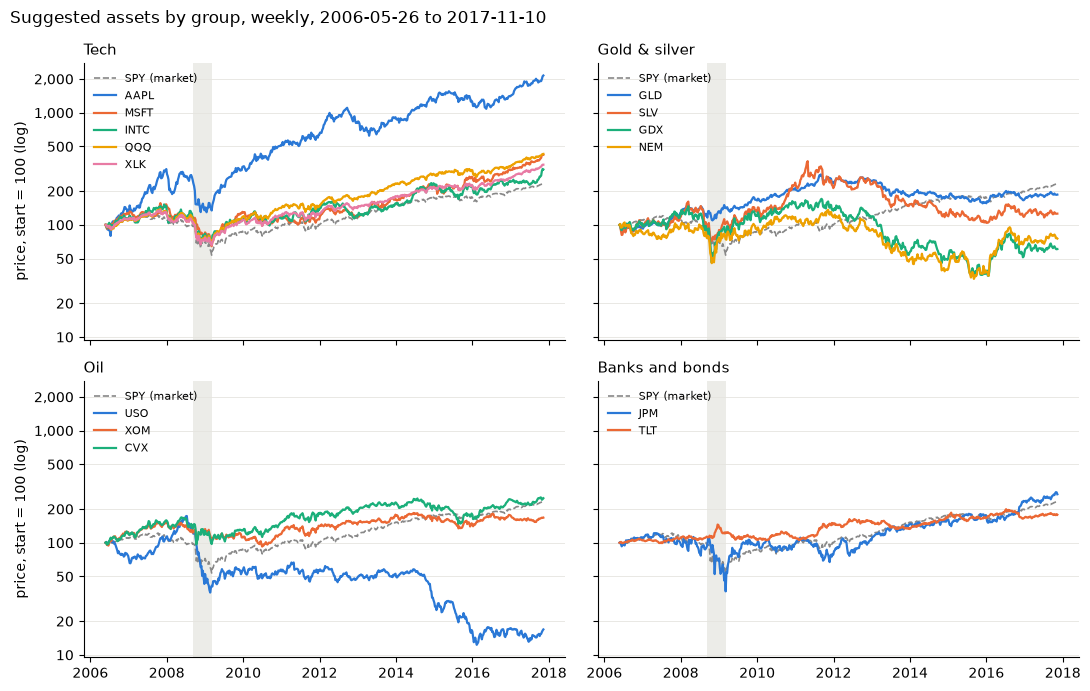

Text summary, average change per group in the 2008 crash window:
  Tech                  -40.5 %
  Gold & silver         +12.0 %
  Oil                   -38.0 %
  Banks                 -61.3 %
  Safe haven (bonds)     +9.8 %
  Market                -45.3 %


In [12]:
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
panels = [("Tech", ["Tech"]), ("Gold & silver", ["Gold & silver"]), ("Oil", ["Oil"]),
          ("Banks and bonds", ["Banks", "Safe haven (bonds)"])]
rebased_k = weekly / weekly.iloc[0] * 100

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (title, groups) in zip(axes.flat, panels):
    ax.axvspan(pd.Timestamp("2008-09-12"), pd.Timestamp("2009-03-06"), color="#e5e4df", alpha=0.7, linewidth=0)
    ax.plot(rebased_k.index, rebased_k["SPY"], color="#888888", linewidth=1.2, linestyle="--", label="SPY (market)")
    members = [t for t in assets.index if assets.loc[t, "group"] in groups]
    for color, ticker in zip(palette, members):
        ax.plot(rebased_k.index, rebased_k[ticker], color=color, linewidth=1.6, label=ticker)
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(FixedLocator([10, 20, 50, 100, 200, 500, 1000, 2000]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_minor_locator(FixedLocator([]))
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("price, start = 100 (log)")
fig.suptitle(f"Suggested assets by group, weekly, {weekly.index[0].date()} to {weekly.index[-1].date()}", x=0.01, ha="left")
fig.tight_layout()
plt.show()

by_group = table.groupby("group", sort=False)["2008 crash (%)"].mean()
print("Text summary, average change per group in the 2008 crash window:")
for group, change in by_group.items():
    print(f"  {group:<20} {change:+6.1f} %")